# Análise de Vendas de Varejo Focada na Rentabilidade das Categorias

## Contexto

O projeto se trata de entender o comportamento de vendas de uma empresa de varejo dos Estados Unidos no período de 2014 até 2018. A realização dessa investigação tem como relevância avaliar o desempenho de diferentes categorias em relação à lucratividade de suas vendas.

## Pergunta de Negócio

Qual é a lucratividade de cada categoria de produto, e quais fatores explicam as diferenças encontradas entre elas?

## Fonte dos Dados

Kaggle: https://www.kaggle.com/datasets/shandeep777/retail-supply-chain-sales-dataset/data

In [5]:
import seaborn as sns 
import matplotlib.pyplot as plt
import pandas as pd

In [6]:
#Carregando o conjunto de dados "Retail-Supply-Chain-Sales-Dataset" 


df = pd.read_excel("../data/Retail-Supply-Chain-Sales-Dataset.xlsx")


In [7]:

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Retail Sales People,Product ID,Category,Sub-Category,Product Name,Returned,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-08-11,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Cassandra Brandow,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,Not,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-08-11,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Cassandra Brandow,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",Not,731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-12-06,2016-12-06,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Anna Andreadi,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,Not,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-11-10,2015-11-10,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Cassandra Brandow,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,Not,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-11-10,2015-11-10,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Cassandra Brandow,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,Not,22.3680,2,0.20,2.5164


## Descrição das Variáveis

O dataset contém 23 colunas no total. As variáveis abaixo são as utilizadas nesta análise:

- **Category**: categoria à qual o produto pertence.
- **Sub-Category**: subdivisão mais específica dentro da categoria (Category).
- **Sales**: valor bruto da venda (receita).
- **Profit**: lucro líquido da venda (pode ser negativo, indicando prejuízo).
- **Discount**: percentual de desconto aplicado na venda.

## Exploração Inicial dos Dados

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Row ID               9994 non-null   int64         
 1   Order ID             9994 non-null   object        
 2   Order Date           9994 non-null   datetime64[ns]
 3   Ship Date            9994 non-null   datetime64[ns]
 4   Ship Mode            9994 non-null   object        
 5   Customer ID          9994 non-null   object        
 6   Customer Name        9994 non-null   object        
 7   Segment              9994 non-null   object        
 8   Country              9994 non-null   object        
 9   City                 9994 non-null   object        
 10  State                9994 non-null   object        
 11  Postal Code          9994 non-null   int64         
 12  Region               9994 non-null   object        
 13  Retail Sales People  9994 non-nul

In [11]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-11 07:17:44.078447104,2016-05-15 21:54:47.332399360,55190.379428,229.858001,3.789574,0.156203,28.656896
min,1.000000,2014-01-02 00:00:00,2014-01-15 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2015-05-01 00:00:00,2015-06-20 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2016-05-30 00:00:00,2016-07-21 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2017-04-09 00:00:00,2017-06-02 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2017-12-30 00:00:00,2018-05-01 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108


In [12]:
df.isnull().sum()

Row ID                 0
Order ID               0
Order Date             0
Ship Date              0
Ship Mode              0
Customer ID            0
Customer Name          0
Segment                0
Country                0
City                   0
State                  0
Postal Code            0
Region                 0
Retail Sales People    0
Product ID             0
Category               0
Sub-Category           0
Product Name           0
Returned               0
Sales                  0
Quantity               0
Discount               0
Profit                 0
dtype: int64

In [13]:
df.duplicated().sum()

0

## Observações

As variáveis apresentam tipos de dados coerentes, com destaque para Order Date e Ship Date, já no formato datetime.

Encontramos um dataset limpo, com zero valores nulos e zero linhas duplicadas. Isso sugere que o conjunto passou por uma etapa de pré-processamento antes de sua disponibilização.

O `describe()` mostra valores extremos, como um lucro mínimo de -6.599,98 e uma venda máxima de 22.638,48, que não foram investigados nesta análise.

## Análise por Categoria

In [16]:
res = df.groupby("Category")[["Sales", "Profit"]].sum()
res["Profit Margin"] = res["Profit"]/res["Sales"]


In [17]:
res["Sales ($)"] = res["Sales"].map(lambda x: f"${x:,.2f}")
res["Profit ($)"] = res["Profit"].map(lambda x: f"${x:,.2f}")
res["Profit Margin %"] = res["Profit Margin"].map(lambda x: f"{x*100:.2f}%")

res[["Sales ($)", "Profit ($)", "Profit Margin %"]]

,Sales ($),Profit ($),Profit Margin %
Category,,,
Furniture,"$741,999.80","$18,451.27",2.49%
Office Supplies,"$719,047.03","$122,490.80",17.04%
Technology,"$836,154.03","$145,454.95",17.40%


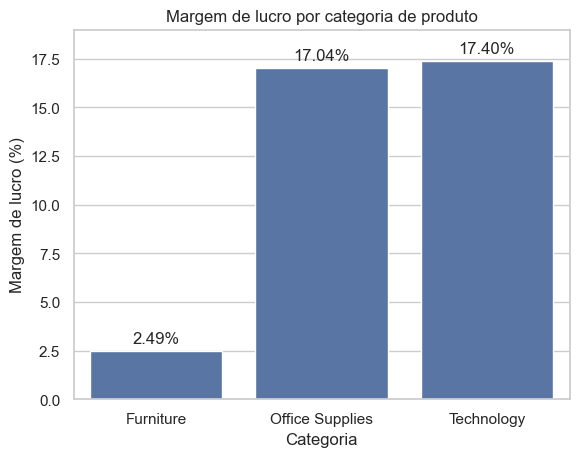

In [18]:



res["Profit Margin (%)"] = res["Profit Margin"] * 100
sns.set_theme(style="whitegrid")
ax = sns.barplot(data=res.reset_index(), x="Category", y="Profit Margin (%)")

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Margem de lucro por categoria de produto")
plt.xlabel("Categoria")
plt.ylabel("Margem de lucro (%)")
plt.ylim(0, 19)
plt.show()


Após a amostragem dos valores de margem de lucro por categoria, nota-se que 'Furniture' tem uma margem de 2,49%, bem abaixo de 'Office Supplies' (17,04%) e 'Technology' (17,40%). Isso sugere a necessidade de investigar as causas dessa baixa rentabilidade.

## Investigação da Categoria Furniture

In [21]:
df_furniture = df[df["Category"] == "Furniture"]


res_subcat = df_furniture.groupby("Sub-Category")[["Sales", "Profit"]].sum()

res_subcat["Profit Margin"] = res_subcat["Profit"]/res_subcat["Sales"]

res_subcat["Discount"] = df_furniture.groupby("Sub-Category")["Discount"].mean()



res_subcat["Sales ($)"] = res_subcat["Sales"].map(lambda x: f"${x:,.2f}")
res_subcat["Profit ($)"] = res_subcat["Profit"].map(lambda x: f"${x:,.2f}")
res_subcat["Profit Margin %"] = res_subcat["Profit Margin"].map(lambda x: f"{x*100:.2f}%") 
res_subcat["Discount %"] = res_subcat["Discount"].map(lambda x: f"{x*100:.2f}%") 



res_subcat[["Sales ($)", "Profit ($)", "Profit Margin %","Discount %"]]



,Sales ($),Profit ($),Profit Margin %,Discount %
Sub-Category,,,,
Bookcases,"$114,880.00","$-3,472.56",-3.02%,21.11%
Chairs,"$328,449.10","$26,590.17",8.10%,17.02%
Furnishings,"$91,705.16","$13,059.14",14.24%,13.83%
Tables,"$206,965.53","$-17,725.48",-8.56%,26.13%


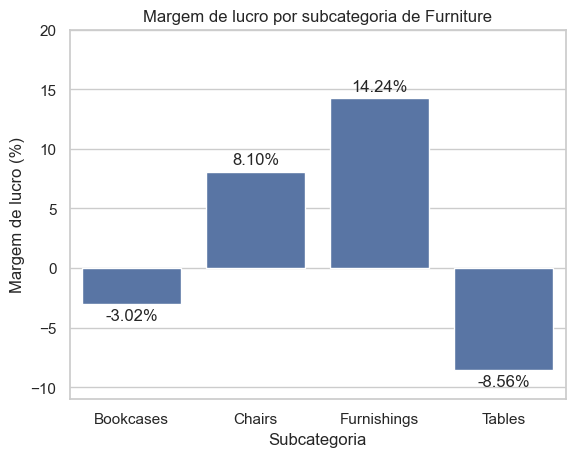

In [22]:
res_subcat["Profit Margin (%)"] = res_subcat["Profit Margin"] * 100
sns.set_theme(style="whitegrid")
ax = sns.barplot(data=res_subcat.reset_index(), x="Sub-Category", y="Profit Margin (%)")

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Margem de lucro por subcategoria de Furniture")
plt.xlabel("Subcategoria")
plt.ylabel("Margem de lucro (%)")
plt.ylim(-11, 20)
plt.show()


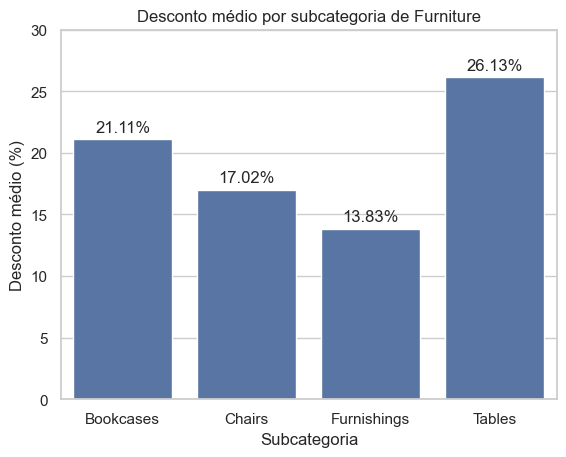

In [23]:
res_subcat["Discount (%)"] = res_subcat["Discount"] * 100
sns.set_theme(style="whitegrid")
ax = sns.barplot(data=res_subcat.reset_index(), x="Sub-Category", y="Discount (%)")

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Desconto médio por subcategoria de Furniture")
plt.xlabel("Subcategoria")
plt.ylabel("Desconto médio (%)")
plt.ylim(0, 30)
plt.show()


Após verificação mais profunda da categoria 'Furniture', ficou visível que as subcategorias 'Bookcases' e 'Tables' apresentam margem de lucro negativa, com -3,02% e -8,56%, respectivamente, enquanto as demais, 'Chairs' e 'Furnishings', demonstram margem positiva, de 8,10% e 14,24%, respectivamente.

As subcategorias com maior desconto médio, 'Tables' (26,13%) e 'Bookcases' (21,11%), são as que apresentam prejuízo, enquanto 'Chairs' (17,02%) e 'Furnishings' (13,83%) têm descontos menores e margem positiva. Isso sugere que descontos médios mais altos estão associados a margens de lucro menores dentro de 'Furniture'.

## Conclusão Final

A categoria 'Furniture' apresentou a menor margem de lucro, de 2,49%, contra 17,04% de 'Office Supplies' e 17,40% de 'Technology'. Dentro de 'Furniture', o prejuízo se concentra em 'Bookcases' e 'Tables', com margens de -3,02% e -8,56%, respectivamente. Essas também são as subcategorias com maior desconto médio (21,11% e 26,13%), o que sugere que descontos mais altos estão associados a margens menores.

Com base nesses resultados, recomenda-se avaliar a política de desconto de 'Bookcases' e 'Tables', verificando se os descontos praticados compensam a margem perdida.

Como próximo passo, seria interessante analisar as colunas 'Order Date' e 'Region', para verificar se o prejuízo e os descontos elevados se mantêm constantes ao longo dos quatro anos ou se pioraram em algum período, e se o prejuízo se concentra em alguma região específica.

Vale ressaltar que a associação entre desconto e margem foi observada em apenas quatro subcategorias, o que limita a confiança nessa associação.